# 06 — Финальный тест на году 2

Год 2 = 2025-10-01 … 2026-09-30. До этого момента он **не использовался** для выбора параметров v2.

| Версия | window | entry_z | Откуда |
|--------|--------|---------|--------|
| v1     | 288    | 2.0     | исходная стратегия |
| v2     | 2016   | 2.5     | выбрана на году 1 (ноутбук 05), зафиксирована коммитом до теста |

Остальные правила у обеих версий одинаковые: выход при z = 0, стоп |z| > 4, time-стоп 2 дня, β = 1, $10,000 на ногу.

**Запускаем один раз, все уровни комиссий. Что бы ни получилось, это и есть результат.**

Оговорка: результат v1 на году 2 уже видели 18.10, для v1 тест не «свежий». Для v2 — первый раз.

## 1. Setup

Тот же setup, что в ноутбуке 05: путь к проекту, данные, фандинг, граница годов.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent                 # notebooks/ → корень проекта
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from datetime import datetime, timezone
import numpy as np
import polars as pl

import config
from src.funding import load_funding, funding_on_bars
from src.signals import log_spread, rolling_zscore
from src.engine_numba import run_backtest_fast
from src.metrics import summary

df = pl.read_parquet(config.PROCESSED_DIR / "pair_5m.parquet")
open_time = df["open_time"].to_numpy()
fa = funding_on_bars(open_time, load_funding(config.SYMBOL_A))     # фандинг ETH на каждой свече
fb = funding_on_bars(open_time, load_funding(config.SYMBOL_B))     # фандинг BTC на каждой свече

oos = datetime.fromisoformat(config.OOS_START).replace(tzinfo=timezone.utc)
split = int((df["open_time"] < int(oos.timestamp() * 1000)).sum())  # первая свеча года 2
assert split == 105_120

open_a, open_b = df["open_a"].to_numpy(), df["open_b"].to_numpy()
close_a, close_b = df["close_a"].to_numpy(), df["close_b"].to_numpy()
tradable = ((df["n_traded_a"] > 0) & (df["n_traded_b"] > 0)).to_numpy()   # обе монеты торговались

print("свечей:", len(df), "| год 1:", split, "| год 2:", len(df) - split)

свечей: 210240 | год 1: 105120 | год 2: 105120


## 2. Функция прогона

`run_period(period)` прогоняет v1 и v2 на заданном отрезке свечей при всех уровнях комиссий.

- z считается на **всех** данных, потом режется. В начале года 2 окно опирается на конец года 1 — это прошлое, утечки нет.
- Капитал в начале каждого отрезка = $20,000.

In [2]:
VERSIONS = {"v1": dict(window=config.WINDOW, entry_z=config.ENTRY_Z),
            "v2": dict(window=config.V2_WINDOW, entry_z=config.V2_ENTRY_Z)}

spread = log_spread(close_a, close_b)                         # β = 1

COLS = ["version", "tier", "n_trades", "win_rate", "avg_trade", "profit_factor",
        "total_return", "max_drawdown", "sharpe", "min_equity"]


def run_period(period):
    """v1 и v2 на отрезке period (slice) при всех уровнях комиссий → таблица метрик."""
    rows = []
    for vname, p in VERSIONS.items():
        z = rolling_zscore(spread, p["window"])
        for tier in config.FEE_TIER_BPS:                      # regular, vip4, vip7
            res = run_backtest_fast(open_a[period], open_b[period], close_a[period], close_b[period],
                                    tradable[period], z[period], tier, fa[period], fb[period],
                                    entry_z=p["entry_z"])
            row = summary(res)
            row.update(version=vname, tier=tier)
            rows.append(row)
    return pl.DataFrame(rows).select(COLS)

## 3. Год 1 — для сравнения

Это уже известные результаты (ноутбук 05). Должно совпасть: v1 VIP-7 −34.7%, v2 VIP-7 −8.1%.
Если совпало — функция считает так же, как в исследовании.

In [3]:
year1 = run_period(slice(0, split))
with pl.Config(tbl_rows=-1):
    print(year1)

shape: (6, 10)
┌─────────┬─────────┬──────────┬──────────┬───┬─────────────┬─────────────┬───────────┬────────────┐
│ version ┆ tier    ┆ n_trades ┆ win_rate ┆ … ┆ total_retur ┆ max_drawdow ┆ sharpe    ┆ min_equity │
│ ---     ┆ ---     ┆ ---      ┆ ---      ┆   ┆ n           ┆ n           ┆ ---       ┆ ---        │
│ str     ┆ str     ┆ i64      ┆ f64      ┆   ┆ ---         ┆ ---         ┆ f64       ┆ f64        │
│         ┆         ┆          ┆          ┆   ┆ f64         ┆ f64         ┆           ┆            │
╞═════════╪═════════╪══════════╪══════════╪═══╪═════════════╪═════════════╪═══════════╪════════════╡
│ v1      ┆ regular ┆ 483      ┆ 0.581781 ┆ … ┆ -0.617264   ┆ -0.631405   ┆ -3.172942 ┆ 7386.37315 │
│         ┆         ┆          ┆          ┆   ┆             ┆             ┆           ┆ 3          │
│ v1      ┆ vip4    ┆ 483      ┆ 0.608696 ┆ … ┆ -0.4239     ┆ -0.442637   ┆ -2.170947 ┆ 11199.7233 │
│         ┆         ┆          ┆          ┆   ┆             ┆             ┆ 

## 4. Год 2 — финальный тест

Запускаем один раз.

In [4]:
year2 = run_period(slice(split, None))
with pl.Config(tbl_rows=-1):
    print(year2)

shape: (6, 10)
┌─────────┬─────────┬──────────┬──────────┬───┬─────────────┬─────────────┬───────────┬────────────┐
│ version ┆ tier    ┆ n_trades ┆ win_rate ┆ … ┆ total_retur ┆ max_drawdow ┆ sharpe    ┆ min_equity │
│ ---     ┆ ---     ┆ ---      ┆ ---      ┆   ┆ n           ┆ n           ┆ ---       ┆ ---        │
│ str     ┆ str     ┆ i64      ┆ f64      ┆   ┆ ---         ┆ ---         ┆ f64       ┆ f64        │
│         ┆         ┆          ┆          ┆   ┆ f64         ┆ f64         ┆           ┆            │
╞═════════╪═════════╪══════════╪══════════╪═══╪═════════════╪═════════════╪═══════════╪════════════╡
│ v1      ┆ regular ┆ 504      ┆ 0.531746 ┆ … ┆ -0.31417    ┆ -0.368839   ┆ -3.30124  ┆ 13609.3470 │
│         ┆         ┆          ┆          ┆   ┆             ┆             ┆           ┆ 99         │
│ v1      ┆ vip4    ┆ 504      ┆ 0.593254 ┆ … ┆ -0.112618   ┆ -0.208714   ┆ -1.121926 ┆ 17564.5937 │
│         ┆         ┆          ┆          ┆   ┆             ┆             ┆ 

## 5. Год 1 и год 2 рядом (VIP-7 и Regular)

Главный вопрос: **v2 лучше v1 и на году 2?**
- да → длинное окно — настоящее улучшение, а не подгонка под год 1;
- нет → улучшение на году 1 было случайностью.

In [5]:
side = (year1.select("version", "tier", pl.col("total_return").alias("y1_return"), pl.col("sharpe").alias("y1_sharpe"))
             .join(year2.select("version", "tier", pl.col("total_return").alias("y2_return"),
                                pl.col("sharpe").alias("y2_sharpe"), pl.col("n_trades").alias("y2_trades")),
                   on=["version", "tier"])
             .sort("tier", "version"))
with pl.Config(tbl_rows=-1):
    print(side)

shape: (6, 7)
┌─────────┬─────────┬───────────┬───────────┬───────────┬───────────┬───────────┐
│ version ┆ tier    ┆ y1_return ┆ y1_sharpe ┆ y2_return ┆ y2_sharpe ┆ y2_trades │
│ ---     ┆ ---     ┆ ---       ┆ ---       ┆ ---       ┆ ---       ┆ ---       │
│ str     ┆ str     ┆ f64       ┆ f64       ┆ f64       ┆ f64       ┆ i64       │
╞═════════╪═════════╪═══════════╪═══════════╪═══════════╪═══════════╪═══════════╡
│ v1      ┆ regular ┆ -0.617264 ┆ -3.172942 ┆ -0.31417  ┆ -3.30124  ┆ 504       │
│ v2      ┆ regular ┆ -0.122934 ┆ -0.914386 ┆ 0.048527  ┆ 0.612847  ┆ 72        │
│ v1      ┆ vip4    ┆ -0.4239   ┆ -2.170947 ┆ -0.112618 ┆ -1.121926 ┆ 504       │
│ v2      ┆ vip4    ┆ -0.09324  ┆ -0.680772 ┆ 0.077297  ┆ 0.947183  ┆ 72        │
│ v1      ┆ vip7    ┆ -0.346554 ┆ -1.758088 ┆ -0.031997 ┆ -0.280084 ┆ 504       │
│ v2      ┆ vip7    ┆ -0.081363 ┆ -0.586816 ┆ 0.088805  ┆ 1.079854  ┆ 72        │
└─────────┴─────────┴───────────┴───────────┴───────────┴───────────┴───────────┘


## 7. Кривая капитала и просадка v1 и v2 за 2 года

Один непрерывный прогон с октября 2024 по сентябрь 2026 (капитал $20,000 в начале).
Пунктир — граница: слева год 1 (подбор параметров), справа год 2 (тест).

In [7]:
import matplotlib.pyplot as plt

full = slice(0, None)                                            # все 2 года
dates = pl.from_epoch(df["open_time"], time_unit="ms").to_numpy()
split_date = dates[split]

curves = {}                                                      # (версия, комиссии) → капитал на каждой свече
for vname, p in VERSIONS.items():
    z = rolling_zscore(spread, p["window"])
    for tier in ("vip7", "regular"):
        res = run_backtest_fast(open_a[full], open_b[full], close_a[full], close_b[full],
                                tradable[full], z[full], tier, fa[full], fb[full],
                                entry_z=p["entry_z"])
        curves[(vname, tier)] = res["equity"]

STYLE = {"vip7": "-", "regular": ":"}                            # сплошная — VIP-7, точки — Regular

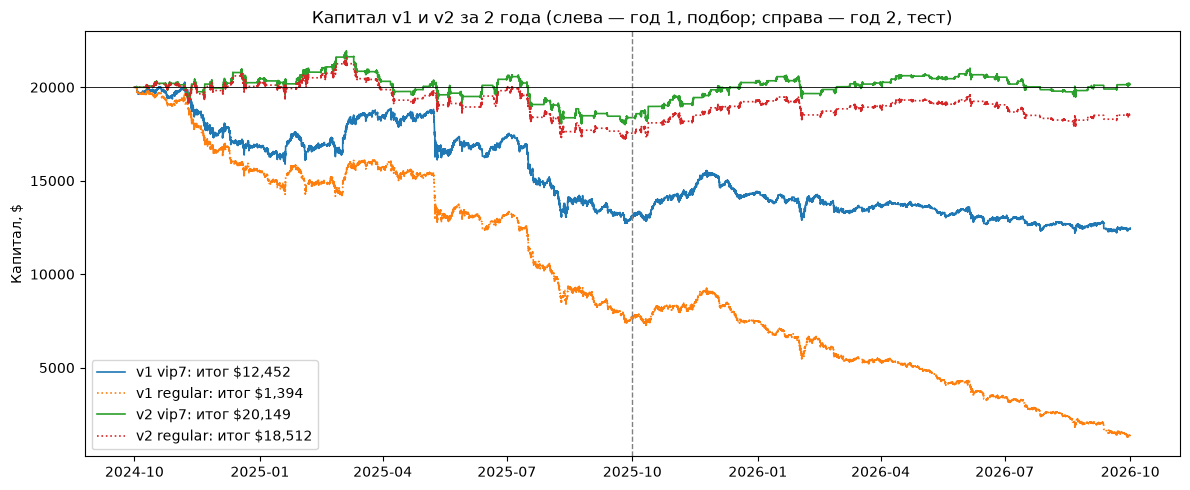

In [8]:
fig, ax = plt.subplots(figsize=(12, 5))

for (vname, tier), eq in curves.items():
    ax.plot(dates, eq, STYLE[tier], lw=1.2, label=f"{vname} {tier}: итог ${eq[-1]:,.0f}")

ax.axvline(split_date, color="grey", ls="--", lw=1)             # граница год 1 / год 2
ax.axhline(config.CAPITAL, color="black", lw=0.6)               # стартовый капитал
ax.set_ylabel("Капитал, $")
ax.set_title("Капитал v1 и v2 за 2 года (слева — год 1, подбор; справа — год 2, тест)")
ax.legend(loc="lower left")

plt.tight_layout()
plt.savefig(ROOT / "reports" / "figures" / "06_equity_v1_v2.png", dpi=150)
plt.show()

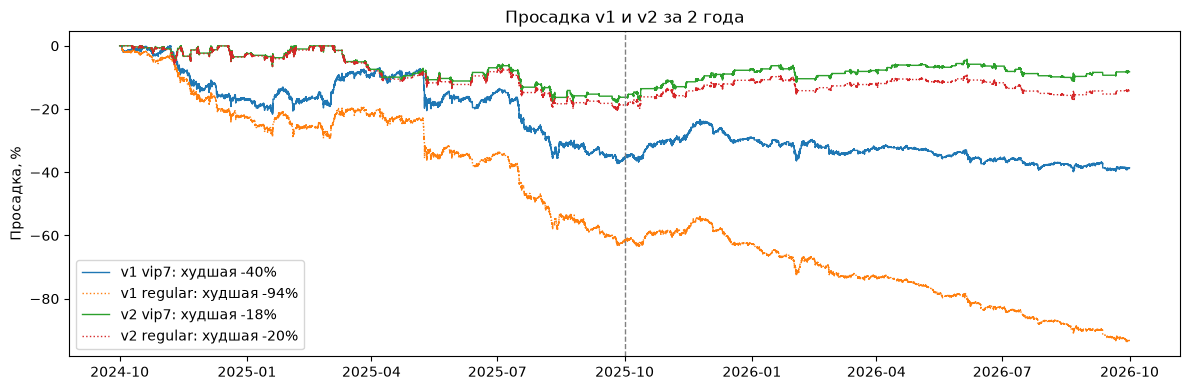

In [9]:
fig, ax = plt.subplots(figsize=(12, 4))

for (vname, tier), eq in curves.items():
    dd = eq / np.maximum.accumulate(eq) - 1                      # насколько ниже прошлого максимума
    ax.plot(dates, dd * 100, STYLE[tier], lw=1.0, label=f"{vname} {tier}: худшая {dd.min():.0%}")

ax.axvline(split_date, color="grey", ls="--", lw=1)             # граница год 1 / год 2
ax.set_ylabel("Просадка, %")
ax.set_title("Просадка v1 и v2 за 2 года")
ax.legend(loc="lower left")

plt.tight_layout()
plt.savefig(ROOT / "reports" / "figures" / "06_drawdown_v1_v2.png", dpi=150)
plt.show()

## 8. Позиции v2 для команды

Тот же формат, что `positions_v1.parquet`: symbol, timestamp, position_qty, close_price —
на каждую 5-минутную свечу, оба года (октябрь 2024 – сентябрь 2026), комиссии VIP-7.
Год 1 — период подбора параметров, год 2 — тест.

In [10]:
from src.export import positions_frame, save_positions

z_v2 = rolling_zscore(spread, config.V2_WINDOW)
res_v2 = run_backtest_fast(open_a, open_b, close_a, close_b, tradable, z_v2, "vip7",
                           fa, fb, entry_z=config.V2_ENTRY_Z)

pos_v2 = positions_frame(df["open_time"].to_numpy(), res_v2["qty_a"], res_v2["qty_b"],
                         close_a, close_b)
save_positions(pos_v2, "positions_v2")
print(pos_v2.shape)                      # ожидаем (420480, 4): 210 240 свечей × 2 монеты
pos_v2.head()

(420480, 4)


symbol,timestamp,position_qty,close_price
str,datetime[μs],f64,f64
"""BTCUSDT""",2024-10-01 00:00:00,0.0,63315.2
"""ETHUSDT""",2024-10-01 00:00:00,0.0,2602.19
"""BTCUSDT""",2024-10-01 00:05:00,0.0,63317.0
"""ETHUSDT""",2024-10-01 00:05:00,0.0,2606.4
"""BTCUSDT""",2024-10-01 00:10:00,0.0,63193.5


In [11]:
print(pos_v2.shape)                                                   # (420480, 4)
in_pos = pos_v2.filter(pl.col("position_qty") != 0)
print("строк с позицией:", in_pos.height, f"({in_pos.height / pos_v2.height:.0%})")
in_pos.head(4)

(420480, 4)
строк с позицией: 110562 (26%)


symbol,timestamp,position_qty,close_price
str,datetime[μs],f64,f64
"""BTCUSDT""",2024-10-09 15:20:00,0.160974,62218.3
"""ETHUSDT""",2024-10-09 15:20:00,-4.067173,2468.53
"""BTCUSDT""",2024-10-09 15:25:00,0.160974,62277.4
"""ETHUSDT""",2024-10-09 15:25:00,-4.067173,2466.41
